# ЛР2 - практика A: Titanic data pipeline

**Курс:** Нейронные сети  
**Статус:** первая самостоятельная часть ЛР2; защита общая после практики B  
**Основные библиотеки:** pandas, NumPy, matplotlib, scikit-learn  
**Датасет:** Titanic (`titanic.csv` из материалов курса)  
**Оборудование:** CPU  
**Интернет:** не требуется

> **Центральный вопрос:**  
> **Как подготовка данных влияет на корректность эксперимента?**

В этой работе один и тот же датасет проходит полный путь:

**сырая таблица → первичный анализ → фиксированный split → preprocessing → baseline → метрики → ошибки → данные для ЛР3.**

Мы не пытаемся изучить все возможности pandas и scikit-learn. Каждый инструмент появляется только тогда, когда он нужен для построения воспроизводимого ML-эксперимента.

## Паспорт работы

| Параметр | Значение |
|---|---|
| Тема | Подготовка табличных данных и классический baseline |
| Максимальный балл | 10 |
| Ожидаемое время | 1.5-2 часа |
| Reference runtime | несколько секунд на обычном CPU |
| Датасет | Titanic, 891 объект |
| Целевая переменная | `Survived` |
| Тип задачи | бинарная классификация |
| Seed | `42` |
| Результат | заполненный notebook + подготовленные массивы для ЛР3 |
| Отдельный Word-отчёт | не требуется |

### После работы вы должны уметь

- быстро исследовать табличный датасет и находить проблемы в данных;
- различать числовые и категориальные признаки;
- корректно делать `train/validation/test` split;
- объяснять, что такое **data leakage**;
- строить воспроизводимый preprocessing через `Pipeline` и `ColumnTransformer`;
- использовать простой baseline и выбирать осмысленные метрики;
- читать confusion matrix и смотреть конкретные ошибки модели;
- подготовить тот же набор данных для последующего сравнения моделей.

## Правила выполнения

- Можно пользоваться документацией, конспектами, примерами библиотек и ИИ-инструментами.
- Вы отвечаете за корректность и понимание всего кода, который сдаёте.
- Ячейки с `TODO` нужно дополнить самостоятельно.
- Не меняйте `SEED`, обязательный набор признаков и стратегию split: результат этой работы будет использован в ЛР3.
- **Test set не используется для выбора решений.** Мы посмотрим на него только после того, как pipeline и baseline будут зафиксированы.
- Существенные внешние источники и использованные ИИ-инструменты перечислите в конце notebook.

# 0. Окружение и воспроизводимость

Данные: `../Task/data/titanic.csv`. Результаты: `artifacts/`. Ядро: `D:/neural networks/.venv/Scripts/python.exe`.

Запускайте ячейки сверху вниз.

In [1]:
SEED = 42

from pathlib import Path
import os
import sys
import random
import platform
import importlib.metadata as md

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
)

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
for package in ["numpy", "pandas", "matplotlib", "scikit-learn"]:
    try:
        print(f"{package}: {md.version(package)}")
    except md.PackageNotFoundError:
        print(f"{package}: not found")

Python: 3.12.6
Platform: Windows-11-10.0.26100-SP0
numpy: 2.5.3
pandas: 3.0.6
matplotlib: 3.11.2
scikit-learn: 1.9.1


# 1. Цель и центральный вопрос

В нейросетевых задачах легко сосредоточиться на архитектуре и забыть, что качество эксперимента начинается **до модели**.

Если preprocessing использует информацию из validation/test, если split каждый раз меняется или если категориальные признаки кодируются непоследовательно, красивое значение метрики перестаёт быть честным сравнением.

> **Центральный вопрос:**  
> **Как подготовка данных влияет на корректность эксперимента?**

К концу работы мы должны получить не только baseline, но и числовые массивы `X_train`, `X_val`, `X_test`,
которые без изменения перейдут в ЛР3.

# 2. Один датасет вместо набора несвязанных упражнений

Мы будем работать с локальным `titanic.csv`.

Каждая строка соответствует пассажиру. Цель `Survived` принимает значения:

- `0` - не выжил;
- `1` - выжил.

Сначала загрузим таблицу и проверим, что это именно ожидаемая версия датасета.

In [2]:
DATA_PATH = Path("../Task/data/titanic.csv")

df = pd.read_csv(DATA_PATH)

expected_columns = {
    "PassengerId", "Survived", "Pclass", "Name", "Sex", "Age",
    "SibSp", "Parch", "Ticket", "Fare", "Cabin", "Embarked"
}
assert expected_columns.issubset(df.columns), "Структура titanic.csv отличается от ожидаемой."

print("Файл:", DATA_PATH.resolve())
print("Размер таблицы:", df.shape)
display(df.head())

Файл: D:\neural networks\Lab 2.1\Task\data\titanic.csv
Размер таблицы: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2.1. Задание 1 - первичная диагностика данных

Не нужно делать полный каталог pandas-операций. Получите только информацию, которая нужна перед построением pipeline.

1. Выведите размер таблицы и типы столбцов.
2. Посчитайте количество пропусков в каждом столбце.
3. Посчитайте число объектов каждого класса и долю `Survived = 1`.
4. Найдите столбцы с особенно большим количеством пропусков.

Используйте компактные выражения pandas: `shape`, `dtypes`, `isna()`, `value_counts()`.

In [3]:
# Размеры, типы, пропуски и баланс классов.
print("Размер:", df.shape)
display(df.dtypes.to_frame("dtype"))
missing_by_column = df.isna().sum()
target_counts = df["Survived"].value_counts().sort_index()
target_share = df["Survived"].mean()
display(missing_by_column.to_frame("missing"))
display(target_counts.to_frame("count"))
print(f"Доля выживших: {target_share:.3f}")


Размер: (891, 12)


,dtype
PassengerId,int64
Survived,int64
Pclass,int64
Name,str
Sex,str
Age,float64
SibSp,int64
Parch,int64
Ticket,str
Fare,float64


,missing
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


,count
Survived,
0,549
1,342


Доля выживших: 0.384


### Интерпретация

Заполните ответы прямо в этой Markdown-ячейке.

1. Какие три столбца содержат пропуски?
2. Какой столбец имеет настолько много пропусков, что в обязательном baseline мы его исключим?
3. Сбалансированы ли классы идеально? Почему одной accuracy в такой задаче может быть недостаточно?

**Ваш ответ:**

Пропуски: Age, Cabin, Embarked. У Cabin отсутствуют 687 из 891 значений, поэтому столбец исключён. Классы: 549 погибших и 342 выживших. Accuracy может скрыть ошибки на меньшем классе.


## 2.2. Фиксируем признаки для обязательного baseline

В реальном проекте выбор признаков сам по себе был бы частью эксперимента. Здесь набор фиксируется,
чтобы в ЛР3 можно было менять **модель**, не меняя входные данные.

| Роль | Признаки |
|---|---|
| Числовые | `Age`, `SibSp`, `Parch`, `Fare` |
| Категориальные | `Pclass`, `Sex`, `Embarked` |
| Не используем в обязательном baseline | `PassengerId`, `Name`, `Ticket`, `Cabin` |
| Target | `Survived` |

`Pclass` хранится как число, но обозначает класс обслуживания, поэтому в этой работе мы трактуем его как категориальный признак.

> Исключение признака не означает, что он «бесполезен вообще». Это лишь фиксированное решение для общего учебного baseline.

In [4]:
TARGET = "Survived"

NUMERIC_FEATURES = ["Age", "SibSp", "Parch", "Fare"]
CATEGORICAL_FEATURES = ["Pclass", "Sex", "Embarked"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

X = df[FEATURES].copy()
y = df[TARGET].copy()

assert X.shape == (891, 7)
assert y.shape == (891,)
assert set(y.unique()) == {0, 1}

display(X.head())

,Age,SibSp,Parch,Fare,Pclass,Sex,Embarked
0,22.0,1,0,7.2500,3,male,S
1,38.0,1,0,71.2833,1,female,C
2,26.0,0,0,7.9250,3,female,S
3,35.0,1,0,53.1000,1,female,S
4,35.0,0,0,8.0500,3,male,S


# 3. Минимальный EDA: график должен отвечать на вопрос

EDA здесь не превращается в отдельную лабораторную по визуализации.

Для начала посмотрим на простой табличный срез: долю выживших в зависимости от пола.

In [5]:
survival_by_sex = (
    df.groupby("Sex")["Survived"]
      .agg(["count", "mean"])
      .rename(columns={"mean": "survival_rate"})
)

display(survival_by_sex)

,count,survival_rate
Sex,,
female,314,0.742038
male,577,0.188908


## 3.1. Задание 2 - три осмысленные визуализации

Постройте:

1. долю выживших для разных значений `Sex`;
2. долю выживших для разных `Pclass`;
3. распределение `Age` отдельно для `Survived = 0` и `Survived = 1`.

Для каждого графика должны быть заголовок и подписи осей.

После графиков сформулируйте **не больше 1-2 предложений на каждый**:
что видно и может ли соответствующий признак быть полезен модели.

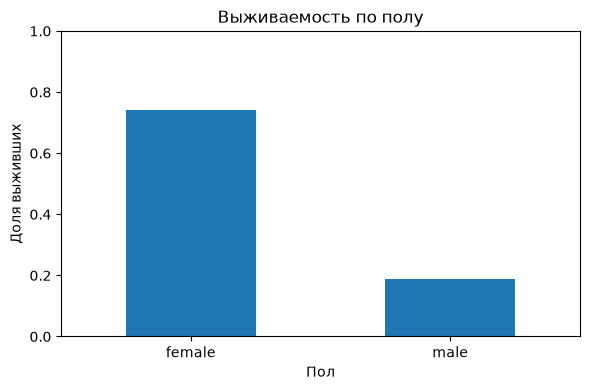

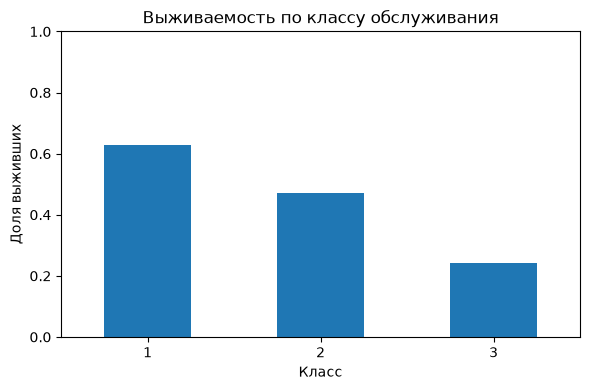

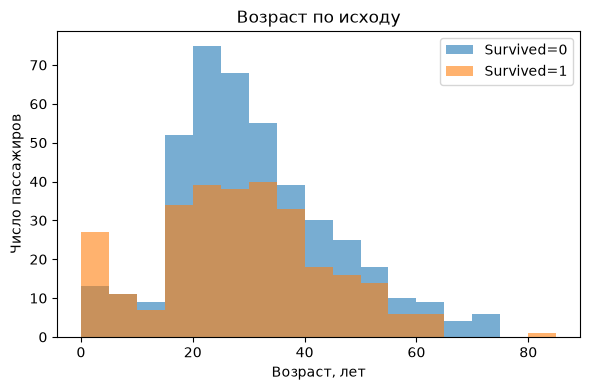

In [6]:
# Выживаемость по полу, классу и распределение возраста.
plt.figure(figsize=(6, 4))
df.groupby("Sex")["Survived"].mean().plot.bar(rot=0)
plt.title("Выживаемость по полу")
plt.xlabel("Пол")
plt.ylabel("Доля выживших")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
df.groupby("Pclass")["Survived"].mean().plot.bar(rot=0)
plt.title("Выживаемость по классу обслуживания")
plt.xlabel("Класс")
plt.ylabel("Доля выживших")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
bins = np.arange(0, 86, 5)
for label in [0, 1]:
    plt.hist(df.loc[df["Survived"].eq(label), "Age"].dropna(),
             bins=bins, alpha=0.6, label=f"Survived={label}")
plt.title("Возраст по исходу")
plt.xlabel("Возраст, лет")
plt.ylabel("Число пассажиров")
plt.legend()
plt.tight_layout()
plt.show()


### Интерпретация EDA

1. Что видно по `Sex`?
2. Что видно по `Pclass`?
3. Насколько очевидна связь `Age` с target только по этому графику?
4. Почему заметная зависимость на графике ещё не доказывает причинную связь?

**Ваш ответ:**

1. Женщины выживали чаще; Sex полезен.
2. Выживаемость в первом классе выше, чем в третьем; Pclass полезен.
3. Возрастные распределения перекрываются. Гистограмма показывает количество, а не долю выживших.
4. Связь может зависеть от других признаков и не доказывает причинность.


# 4. Фиксируем train / validation / test

Теперь начинается собственно эксперимент.

Используем:

- `train` - 70%;
- `validation` - 15%;
- `test` - 15%;
- `random_state = 42`;
- `stratify = y`.

**Validation** используется для анализа baseline и принятия решений.  
**Test** считаем отложенной финальной проверкой: до раздела 8 мы к его метрикам не обращаемся.

Важный принцип:

> Все статистики preprocessing - медианы, средние, параметры scaling, категории для encoding - должны оцениваться **только по train**.

## 4.1. Задание 3 - создать воспроизводимый split

Сначала отделите 15% test. Затем разделите оставшиеся 85% так, чтобы validation составлял 15% от всей выборки.

Сохраняйте именно **индексы строк**:

- `train_idx`
- `val_idx`
- `test_idx`

После этого создайте `X_train`, `X_val`, `X_test`, `y_train`, `y_val`, `y_test`.

Используйте `stratify` на обоих этапах.

In [7]:
# Стратифицированный split 70/15/15 с фиксированным seed.
all_idx = np.arange(len(df))
train_val_idx, test_idx = train_test_split(
    all_idx, test_size=0.15, random_state=SEED, stratify=y,
)
train_idx, val_idx = train_test_split(
    train_val_idx, test_size=0.15 / 0.85, random_state=SEED,
    stratify=y.iloc[train_val_idx],
)
X_train, X_val, X_test = [X.iloc[idx].copy() for idx in [train_idx, val_idx, test_idx]]
y_train, y_val, y_test = [y.iloc[idx].copy() for idx in [train_idx, val_idx, test_idx]]


In [8]:
split_summary = pd.DataFrame({
    "split": ["train", "validation", "test"],
    "n": [len(y_train), len(y_val), len(y_test)],
    "share": [len(y_train) / len(y), len(y_val) / len(y), len(y_test) / len(y)],
    "survived_rate": [y_train.mean(), y_val.mean(), y_test.mean()],
})

display(split_summary)

assert len(train_idx) + len(val_idx) + len(test_idx) == len(df)
assert set(train_idx).isdisjoint(val_idx)
assert set(train_idx).isdisjoint(test_idx)
assert set(val_idx).isdisjoint(test_idx)

,split,n,share,survived_rate
0,train,623,0.699214,0.383628
1,validation,134,0.150393,0.388060
2,test,134,0.150393,0.380597


### Почему здесь нужен `stratify`?

Ответьте до перехода дальше.

1. Что сохраняет `stratify=y`?
2. Особенно когда это важно?
3. Почему недостаточно один раз «удачно» получить похожие доли классов без фиксированного seed?

**Ваш ответ:**

stratify сохраняет близкие доли классов. Это важно при дисбалансе и малой выборке. Seed фиксирует разбиение для повторных сравнений.


# 5. Data leakage: маленькая утечка всё равно остаётся утечкой

Рассмотрим очень простой пример.

`Age` содержит пропуски. Если мы решили заполнять их медианой, возникает вопрос:

> **По каким данным считать медиану?**

Посчитаем два значения - пока только для демонстрации.

In [9]:
full_age_median = df["Age"].median()
train_age_median = X_train["Age"].median()

print("Медиана Age по ВСЕМ данным:", full_age_median)
print("Медиана Age только по TRAIN:", train_age_median)

Медиана Age по ВСЕМ данным: 28.0
Медиана Age только по TRAIN: 29.0


### Интерпретация leakage

1. Почему использовать `full_age_median` для заполнения пропусков было бы методически неправильно?
2. Делает ли небольшая разница между двумя медианами такую утечку допустимой?
3. Что изменится, если preprocessing будет оформлен как часть sklearn `Pipeline`?

**Ваш ответ:**

Медиана всей таблицы использует validation/test. Малое различие медиан не устраняет утечку. Pipeline предотвращает её только при fit на train.


# 6. Preprocessing: разные признаки - разные преобразования

Наши признаки неоднородны.

Числовая ветка:

```text
Age, SibSp, Parch, Fare
        ↓
SimpleImputer(strategy="median")
        ↓
StandardScaler
```

Категориальная ветка:

```text
Pclass, Sex, Embarked
        ↓
SimpleImputer(strategy="most_frequent")
        ↓
OneHotEncoder(handle_unknown="ignore")
```

Обе ветки объединяются через `ColumnTransformer`.

`handle_unknown="ignore"` важен потому, что validation/test теоретически могут содержать категорию,
которой не было в train.

## 6.1. Задание 4 - собрать `ColumnTransformer`

Создайте функцию `make_preprocessor()`, которая каждый раз возвращает **новый** preprocessing pipeline.

Требования:

- числовые пропуски → median;
- числовые признаки → `StandardScaler`;
- категориальные пропуски → most frequent;
- категориальные признаки → `OneHotEncoder`;
- `sparse_output=False`;
- неизвестные категории не должны приводить к ошибке.

После этого создайте `preprocessor = make_preprocessor()`.

In [10]:
# Отдельные преобразования числовых и категориальных признаков.
def make_preprocessor():
    numeric = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([
        ("num", numeric, NUMERIC_FEATURES),
        ("cat", categorical, CATEGORICAL_FEATURES),
    ])


preprocessor = make_preprocessor()


## 6.2. Fit только на train

Теперь важен не только **какой** метод вызвать, но и **на каких данных**.

Сделайте:

```python
X_train_prepared = preprocessor.fit_transform(X_train)
X_val_prepared   = preprocessor.transform(X_val)
X_test_prepared  = preprocessor.transform(X_test)
```

Обратите внимание: `fit_transform` вызывается только для train.

In [11]:
# Fit только на train, остальные выборки только transform.
X_train_prepared = preprocessor.fit_transform(X_train)
X_val_prepared = preprocessor.transform(X_val)
X_test_prepared = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()


In [12]:
print("До preprocessing:", X_train.shape)
print("После preprocessing:", X_train_prepared.shape)
print("\nИтоговые признаки:")
print(feature_names)

assert X_train_prepared.shape[0] == len(y_train)
assert X_val_prepared.shape[0] == len(y_val)
assert X_test_prepared.shape[0] == len(y_test)

assert X_train_prepared.shape[1] == X_val_prepared.shape[1] == X_test_prepared.shape[1]
assert np.isfinite(X_train_prepared).all()
assert np.isfinite(X_val_prepared).all()
assert np.isfinite(X_test_prepared).all()

До preprocessing: (623, 7)
После preprocessing: (623, 12)

Итоговые признаки:
['num__Age' 'num__SibSp' 'num__Parch' 'num__Fare' 'cat__Pclass_1'
 'cat__Pclass_2' 'cat__Pclass_3' 'cat__Sex_female' 'cat__Sex_male'
 'cat__Embarked_C' 'cat__Embarked_Q' 'cat__Embarked_S']


### Что произошло с размерностью?

Исходно было 7 признаков, после preprocessing их стало больше.

1. Почему?
2. Какой именно преобразователь увеличил число столбцов?
3. Почему `Pclass` дал несколько выходных признаков?
4. Что означает `num__` и `cat__` в `feature_names`?

**Ваш ответ:**

Получено 12 столбцов: 4 числовых и 8 one-hot. Pclass даёт 3 категории, Sex даёт 2, Embarked даёт 3. num__ и cat__ обозначают ветки ColumnTransformer.


# 7. Baseline: сначала проверяем, лучше ли модель тривиального решения

Число `accuracy = 0.80` само по себе мало что говорит.

Сначала построим **DummyClassifier**, который всегда выбирает самый частый класс.
После этого сравним его с Logistic Regression.

Основные метрики:

- **accuracy** - доля правильных ответов;
- **F1** - баланс precision и recall для положительного класса;
- **confusion matrix** - какие именно ошибки делает модель.

In [13]:
def get_metrics(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred),
    }

## 7.1. Задание 5 - Dummy baseline

Обучите:

```python
DummyClassifier(strategy="most_frequent")
```

на `y_train`.

Поскольку DummyClassifier фактически игнорирует признаки, можно передать ему
`X_train_prepared` и затем получить `dummy_val_pred` для `X_val_prepared`.

Сохраните метрики в `dummy_val_metrics`.

In [14]:
# Тривиальный baseline на validation.
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train_prepared, y_train)
dummy_val_pred = dummy.predict(X_val_prepared)
dummy_val_metrics = get_metrics(y_val, dummy_val_pred)


## 7.2. Задание 6 - Logistic Regression внутри полного Pipeline

Теперь соберите модель так, чтобы preprocessing и классификатор были единым объектом:

```text
raw DataFrame
    ↓
ColumnTransformer
    ↓
LogisticRegression
```

Создайте `logreg_pipeline`, обучите его **на raw `X_train`** и получите `logreg_val_pred` для raw `X_val`.

Используйте:

```python
LogisticRegression(max_iter=1000, random_state=SEED)
```

Сохраните метрики в `logreg_val_metrics`.

In [15]:
# Полный pipeline с логистической регрессией.
logreg_pipeline = Pipeline([
    ("preprocessor", make_preprocessor()),
    ("model", LogisticRegression(max_iter=1000, random_state=SEED)),
])
logreg_pipeline.fit(X_train, y_train)
logreg_val_pred = logreg_pipeline.predict(X_val)
logreg_val_metrics = get_metrics(y_val, logreg_val_pred)


,accuracy,f1
DummyClassifier,0.612,0.000
LogisticRegression,0.836,0.792


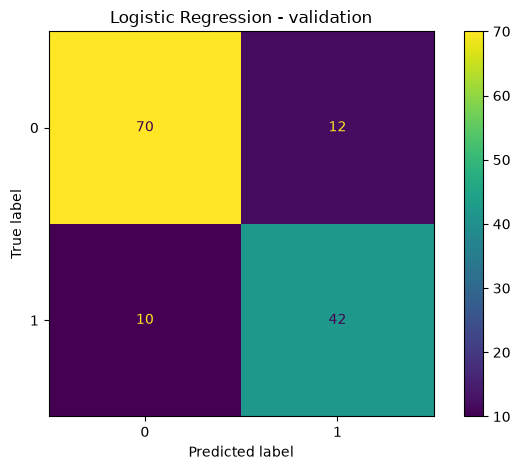

In [16]:
val_results = pd.DataFrame(
    [dummy_val_metrics, logreg_val_metrics],
    index=["DummyClassifier", "LogisticRegression"],
)

display(val_results.round(3))

ConfusionMatrixDisplay.from_predictions(y_val, logreg_val_pred)
plt.title("Logistic Regression - validation")
plt.tight_layout()
plt.show()

### Интерпретация validation-результата

1. Почему у DummyClassifier может быть не совсем маленькая accuracy, но F1 равен нулю?
2. Лучше ли Logistic Regression тривиального baseline? По каким признакам вы это решили?
3. Какой тип ошибок виден в confusion matrix?
4. Почему сейчас мы смотрим validation, а не test?

**Ваш ответ:**

Dummy предсказывает только 0: accuracy=0.612, F1=0. Logistic Regression лучше: accuracy=0.836, F1=0.792. На validation FP=12, FN=10. Validation используется для анализа, test для финальной оценки.


# 8. Порог решения: одна вероятность - разные precision и recall

`LogisticRegression` умеет выдавать не только готовый класс, но и оценку вероятности положительного класса через `predict_proba`. Класс по умолчанию получается при пороге около `0.5`, но сам порог - часть правила принятия решения.

На **validation** сравните три порога: `0.3`, `0.5`, `0.7`. Для каждого посчитайте `precision` и `recall`. Затем постройте ROC-кривую и получите ROC-AUC по вероятностям. Test пока не используем.

> Смысл блока - увидеть компромисс: снижение порога обычно помогает находить больше положительных объектов (recall), но может увеличить число false positive и снизить precision.


## 8.1. Задание 7 - threshold, precision/recall и ROC-AUC

1. Получите `logreg_val_proba` - вероятность класса `1` для `X_val`.
2. Для порогов `0.3`, `0.5`, `0.7` сформируйте бинарные предсказания и соберите таблицу `threshold_metrics` со столбцами `threshold`, `precision`, `recall`.
3. Посчитайте `val_roc_auc = roc_auc_score(y_val, logreg_val_proba)`.
4. Постройте ROC-кривую.


,threshold,precision,recall
0,0.3,0.657,0.885
1,0.5,0.778,0.808
2,0.7,0.878,0.692


ROC-AUC: 0.892


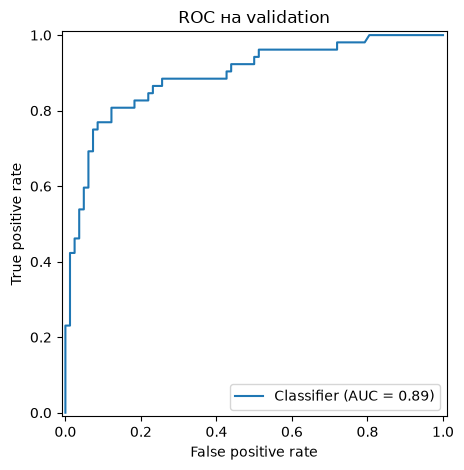

In [17]:
# Пороги и ROC-AUC оцениваются только на validation.
logreg_val_proba = logreg_pipeline.predict_proba(X_val)[:, 1]
threshold_metrics = pd.DataFrame([
    {
        "threshold": threshold,
        "precision": precision_score(y_val, logreg_val_proba >= threshold, zero_division=0),
        "recall": recall_score(y_val, logreg_val_proba >= threshold, zero_division=0),
    }
    for threshold in [0.3, 0.5, 0.7]
])
val_roc_auc = roc_auc_score(y_val, logreg_val_proba)
display(threshold_metrics.round(3))
print(f"ROC-AUC: {val_roc_auc:.3f}")
RocCurveDisplay.from_predictions(y_val, logreg_val_proba)
plt.title("ROC на validation")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.tight_layout()
plt.show()


### Интерпретация порога

1. Как изменились precision и recall при переходе от `0.3` к `0.7`?
2. Какой порог вы бы выбрали, если false negative особенно дороги? Почему?
3. Почему ROC-AUC считается по вероятностям и не привязан к одному выбранному threshold?
4. Почему выбирать threshold по test было бы нарушением роли test?

**Ваш ответ:**

При росте порога precision вырос, recall снизился. При дорогих FN подходит 0.3: recall выше. ROC-AUC оценивает ранжирование при разных порогах. Порог нельзя выбирать по test. Для финальной оценки сохранён порог 0.5.


# 9. Финальная проверка на test и несколько реальных ошибок

Pipeline зафиксирован. Только теперь используем test.

Мы не будем менять признаки или параметры Logistic Regression после просмотра test-метрик:
иначе test постепенно превратится ещё в один validation set.

## 9.1. Задание 8 - test metrics

Получите:

- `test_pred`;
- `test_metrics`.

Выведите accuracy, F1 и confusion matrix.

,test
accuracy,0.776
f1,0.681


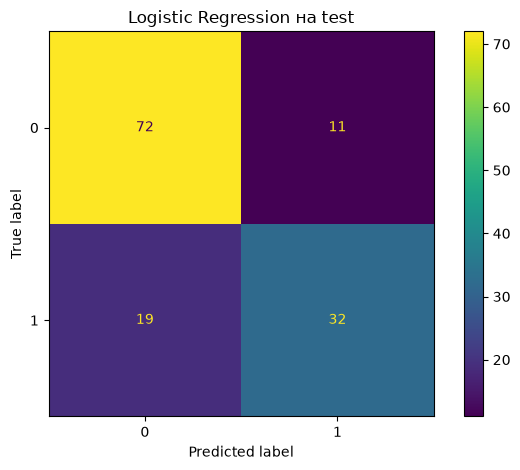

In [18]:
# Финальная test-оценка зафиксированной модели при пороге 0.5.
test_pred = logreg_pipeline.predict(X_test)
test_metrics = get_metrics(y_test, test_pred)
display(pd.Series(test_metrics).round(3).to_frame("test"))
ConfusionMatrixDisplay.from_predictions(y_test, test_pred)
plt.title("Logistic Regression на test")
plt.tight_layout()
plt.show()


## 9.2. Посмотреть на конкретные ошибки

Aggregate-метрики полезны, но не показывают сами объекты.

Создайте `errors`, где будут исходные признаки test, правильный класс `y_true`,
предсказание `y_pred` и только ошибочно классифицированные строки.

Покажите минимум 5 ошибок.

In [19]:
# Исходные признаки ошибочных объектов, отдельно FP и FN.
errors = X_test.copy()
errors["y_true"] = y_test
errors["y_pred"] = test_pred
errors = errors.loc[errors["y_true"].ne(errors["y_pred"])].copy()
display(errors.groupby("y_true", group_keys=False).head(5))
print("Число ошибок:", len(errors))
display(errors.groupby(["Sex", "Pclass", "y_true"]).size().rename("errors").to_frame())


,Age,SibSp,Parch,Fare,Pclass,Sex,Embarked,y_true,y_pred
553,22.0,0,0,7.2250,3,male,C,1,0
279,35.0,1,1,20.2500,3,female,S,1,0
455,29.0,0,0,7.8958,3,male,C,1,0
701,35.0,0,0,26.2875,1,male,S,1,0
549,8.0,1,1,36.7500,2,male,S,1,0
297,2.0,1,2,151.5500,1,female,S,0,1
501,21.0,0,0,7.7500,3,female,Q,0,1
452,30.0,0,0,27.7500,1,male,C,0,1
634,9.0,3,2,27.9000,3,female,S,0,1
199,24.0,0,0,13.0000,2,female,S,0,1


Число ошибок: 30


errors
Sex    Pclass y_true        
female 1      0            1
       2      0            1
       3      0            7
              1            2
male   1      0            2
              1            7
       2      1            2
       3      1            8

### Короткий анализ ошибок

Посмотрите на несколько false positive и false negative.

1. Есть ли среди ошибок группы, которые повторяются?
2. Можно ли по нескольким строкам уверенно объяснить причину каждой ошибки?
3. Почему анализ отдельных объектов дополняет confusion matrix, но не заменяет её?

**Ваш ответ:**

Чаще встречаются выжившие мужчины третьего класса: 8 ошибок. Это число ошибок, а не их доля внутри группы. Причины по нескольким строкам не устанавливаются. Примеры дополняют общую confusion matrix.


# 10. Передаём те же данные в ЛР3

В следующей лабораторной мы будем сравнивать MLP из sklearn и PyTorch.

Чтобы сравнение было честным, **данные не будем готовить заново**.
Используем fitted preprocessing из `logreg_pipeline` и сохраним:

- `X_train`, `X_val`, `X_test` после preprocessing;
- `y_train`, `y_val`, `y_test`;
- имена итоговых признаков;
- отдельную таблицу `PassengerId → split`.

Так в ЛР3 изменится модель, а не исходные условия эксперимента.

In [20]:
ARTIFACT_DIR = Path("artifacts")
ARTIFACT_DIR.mkdir(exist_ok=True)

fitted_preprocessor = logreg_pipeline.named_steps["preprocessor"]

X_train_lr3 = np.asarray(
    fitted_preprocessor.transform(X_train), dtype=np.float32
)
X_val_lr3 = np.asarray(
    fitted_preprocessor.transform(X_val), dtype=np.float32
)
X_test_lr3 = np.asarray(
    fitted_preprocessor.transform(X_test), dtype=np.float32
)

feature_names_lr3 = np.asarray(
    fitted_preprocessor.get_feature_names_out(), dtype=str
)

np.savez_compressed(
    ARTIFACT_DIR / "lr2_titanic_prepared.npz",
    X_train=X_train_lr3,
    X_val=X_val_lr3,
    X_test=X_test_lr3,
    y_train=y_train.to_numpy(dtype=np.int64),
    y_val=y_val.to_numpy(dtype=np.int64),
    y_test=y_test.to_numpy(dtype=np.int64),
    feature_names=feature_names_lr3,
)

split_labels = np.empty(len(df), dtype=object)
split_labels[train_idx] = "train"
split_labels[val_idx] = "validation"
split_labels[test_idx] = "test"

split_table = pd.DataFrame({
    "PassengerId": df["PassengerId"],
    "split": split_labels,
})

split_table.to_csv(
    ARTIFACT_DIR / "lr2_titanic_split.csv",
    index=False,
)

print("Сохранено:")
for path in sorted(ARTIFACT_DIR.iterdir()):
    print(" -", path)

Сохранено:
 - artifacts\lr2_titanic_prepared.npz
 - artifacts\lr2_titanic_split.csv


In [21]:
# Финальные sanity checks

assert X_train_lr3.dtype == np.float32
assert X_val_lr3.dtype == np.float32
assert X_test_lr3.dtype == np.float32

assert X_train_lr3.shape[1] == X_val_lr3.shape[1] == X_test_lr3.shape[1]
assert len(feature_names_lr3) == X_train_lr3.shape[1]

assert np.isfinite(X_train_lr3).all()
assert np.isfinite(X_val_lr3).all()
assert np.isfinite(X_test_lr3).all()

assert len(split_table) == len(df)
assert set(split_table["split"]) == {"train", "validation", "test"}

with np.load(ARTIFACT_DIR / "lr2_titanic_prepared.npz") as saved:
    assert saved["X_train"].shape == X_train_lr3.shape
    assert saved["y_train"].shape == y_train.shape

print("Финальные проверки пройдены.")

Финальные проверки пройдены.


# 11. Вывод

Ответьте коротко, но содержательно - примерно 8-12 предложений суммарно.

1. **Ответ на центральный вопрос:** как подготовка данных влияет на корректность эксперимента?
2. Зачем split выполняется до вычисления статистик preprocessing?
3. Как `Pipeline` снижает риск leakage и делает эксперимент воспроизводимым?
4. Зачем нужен DummyClassifier, если мы всё равно хотим использовать более сильную модель?
5. Что показало изменение threshold о компромиссе precision/recall и что дополнительно сообщает ROC-AUC?
6. Что именно мы зафиксировали для честного сравнения моделей в ЛР3?

**Ваш вывод:**

Подготовка данных определяет корректность оценки. Split фиксируется до обучения preprocessing. Pipeline обучается только на train и снижает риск утечки. Пропуски заполнены, числа масштабированы, категории закодированы one-hot. DummyClassifier задаёт ориентир для сравнения. Logistic Regression лучше baseline: test accuracy=0.776, F1=0.681. Снижение порога повышает recall ценой дополнительных FP. ROC-AUC=0.892 оценивает ранжирование без одного фиксированного порога. Для ЛР3 сохранены массивы, метки, имена признаков и split PassengerId.


# 12. Источники и использованные инструменты

- Материалы: `../Task/student.ipynb`, `../Task/demo.ipynb`, `../Task/data/titanic.csv`.
- ИИ: ChatGPT (Codex), реализация, пояснения и проверка.
- Другие внешние источники не использовались.


# 13. Завершение практики A и подготовка к практике B

| Компонент | Баллы | Что проверяется в ЛР2 |
|---|---:|---|
| Корректность реализации | 3 | EDA, split, preprocessing, Pipeline, baseline, threshold/ROC-AUC и экспорт данных |
| Эксперимент и метрики | 2 | честный split, отсутствие leakage, Dummy vs Logistic Regression, метрики |
| Анализ и выводы | 1 | интерпретация EDA, confusion matrix, ошибок и центрального вопроса |
| Устная защита | 4 | понимание split, preprocessing, leakage, encoding, scaling и метрик |

**Hard gate:** менее **2 из 4** баллов за устную часть - лабораторная не засчитывается.

На защите будьте готовы:

- объяснить, почему конкретный столбец числовой/категориальный/исключённый;
- объяснить разницу между `fit_transform` и `transform`;
- показать, где именно preprocessing обучается только на train;
- объяснить `stratify`, validation и test;
- интерпретировать confusion matrix;
- выполнить небольшое live-изменение и заранее спрогнозировать его эффект.

---

### Самопроверка перед сдачей

- [x] Все `TODO` заполнены.
- [x] Notebook запускается сверху вниз без ошибок.
- [x] Используется `SEED = 42`.
- [x] Train / validation / test не пересекаются.
- [x] Preprocessing обучается только на train.
- [x] Test не использовался для выбора решений до финальной оценки.
- [x] Есть 3 осмысленные визуализации и краткая интерпретация.
- [x] DummyClassifier сравнивается с Logistic Regression.
- [x] Посчитаны accuracy, F1 и confusion matrix.
- [x] Просмотрены конкретные ошибки модели.
- [x] Созданы `artifacts/lr2_titanic_prepared.npz` и `artifacts/lr2_titanic_split.csv`.
- [x] Написан ответ на центральный вопрос.
- [x] Указаны существенные источники и ИИ-инструменты.
- [ ] Готовность объяснить и изменить код проверена самостоятельно.